# Spotify Tracks — Feature Correlation Heatmap

Interactive exploration of audio-feature relationships in the Ultimate Spotify Tracks dataset.

In [1]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

/Users/samuelmorales/lab3-groupa/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Load dataset

In [2]:
dataset_path = Path(kagglehub.dataset_download("zaheenhamidani/ultimate-spotify-tracks-db"))
csv_files = list(dataset_path.rglob("*.csv"))
if len(csv_files) != 1:
    raise RuntimeError(f"Expected one CSV; found: {csv_files}")

df = pd.read_csv(csv_files[0])
print(f"Loaded {df.shape[0]:,} tracks and {df.shape[1]} columns from {csv_files[0].name}")
df.head()

  0%|          | 0.00/15.5M [00:00<?, ?B/s]

 13%|█▎        | 2.00M/15.5M [00:00<00:00, 14.7MB/s]

 26%|██▌       | 4.00M/15.5M [00:00<00:00, 16.8MB/s]

 39%|███▉      | 6.00M/15.5M [00:00<00:00, 16.8MB/s]

 52%|█████▏    | 8.00M/15.5M [00:00<00:00, 17.7MB/s]

 65%|██████▍   | 10.0M/15.5M [00:00<00:00, 18.1MB/s]

... (2 outputs left out)

100%|██████████| 15.5M/15.5M [00:01<00:00, 15.1MB/s]

Extracting files...


Loaded 232,725 tracks and 18 columns from SpotifyFeatures.csv


,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
0,Movie,Henri Salvador,C'est beau de faire un Show,0BRjO6ga9RKCKjfDqeFgWV,0,0.611,0.389,99373,0.910,0.000,C#,0.3460,-1.828,Major,0.0525,166.969,4/4,0.814
1,Movie,Martin & les fées,Perdu d'avance (par Gad Elmaleh),0BjC1NfoEOOusryehmNudP,1,0.246,0.590,137373,0.737,0.000,F#,0.1510,-5.559,Minor,0.0868,174.003,4/4,0.816
2,Movie,Joseph Williams,Don't Let Me Be Lonely Tonight,0CoSDzoNIKCRs124s9uTVy,3,0.952,0.663,170267,0.131,0.000,C,0.1030,-13.879,Minor,0.0362,99.488,5/4,0.368
3,Movie,Henri Salvador,Dis-moi Monsieur Gordon Cooper,0Gc6TVm52BwZD07Ki6tIvf,0,0.703,0.240,152427,0.326,0.000,C#,0.0985,-12.178,Major,0.0395,171.758,4/4,0.227
4,Movie,Fabien Nataf,Ouverture,0IuslXpMROHdEPvSl1fTQK,4,0.950,0.331,82625,0.225,0.123,F,0.2020,-21.150,Major,0.0456,140.576,4/4,0.390


## Brief description of the dataset

This notebook uses the **Ultimate Spotify Tracks DB** from Kaggle
(`zaheenhamidani/ultimate-spotify-tracks-db`). Each row is a track with metadata
(genre, artist, track name) and Spotify audio features such as:

- **popularity** — Spotify popularity score (0–100)
- **acousticness**, **danceability**, **energy**, **instrumentalness**, **liveness**, **speechiness**, **valence** — continuous audio attributes (typically 0–1)
- **loudness** — overall loudness in dB
- **tempo** — estimated tempo in BPM
- **duration_ms** — track length in milliseconds

The dataset is useful for studying how musical attributes relate to each other and to popularity across genres.

In [3]:
df.info()
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232725 entries, 0 to 232724
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   genre             232725 non-null  object 
 1   artist_name       232725 non-null  object 
 2   track_name        232724 non-null  object 
 3   track_id          232725 non-null  object 
 4   popularity        232725 non-null  int64  
 5   acousticness      232725 non-null  float64
 6   danceability      232725 non-null  float64
 7   duration_ms       232725 non-null  int64  
 8   energy            232725 non-null  float64
 9   instrumentalness  232725 non-null  float64
 10  key               232725 non-null  object 
 11  liveness          232725 non-null  float64
 12  loudness          232725 non-null  float64
 13  mode              232725 non-null  object 
 14  speechiness       232725 non-null  float64
 15  tempo             232725 non-null  float64
 16  time_signature    23

,count,mean,std,min,25%,50%,75%,max
popularity,232725.0,41.127502,18.189948,0.00000,29.0000,43.000000,55.0000,100.000
acousticness,232725.0,0.368560,0.354768,0.00000,0.0376,0.232000,0.7220,0.996
danceability,232725.0,0.554364,0.185608,0.05690,0.4350,0.571000,0.6920,0.989
duration_ms,232725.0,235122.339306,118935.909299,15387.00000,182857.0000,220427.000000,265768.0000,5552917.000
energy,232725.0,0.570958,0.263456,0.00002,0.3850,0.605000,0.7870,0.999
instrumentalness,232725.0,0.148301,0.302768,0.00000,0.0000,0.000044,0.0358,0.999
liveness,232725.0,0.215009,0.198273,0.00967,0.0974,0.128000,0.2640,1.000
loudness,232725.0,-9.569885,5.998204,-52.45700,-11.7710,-7.762000,-5.5010,3.744
speechiness,232725.0,0.120765,0.185518,0.02220,0.0367,0.050100,0.1050,0.967
tempo,232725.0,117.666585,30.898907,30.37900,92.9590,115.778000,139.0540,242.903


## Visualization: correlation heatmap of audio features

We compute Pearson correlations among numeric audio features and visualize them
as a heatmap. Strong positive values (near +1) mean features rise together;
strong negative values (near −1) mean they move in opposite directions.

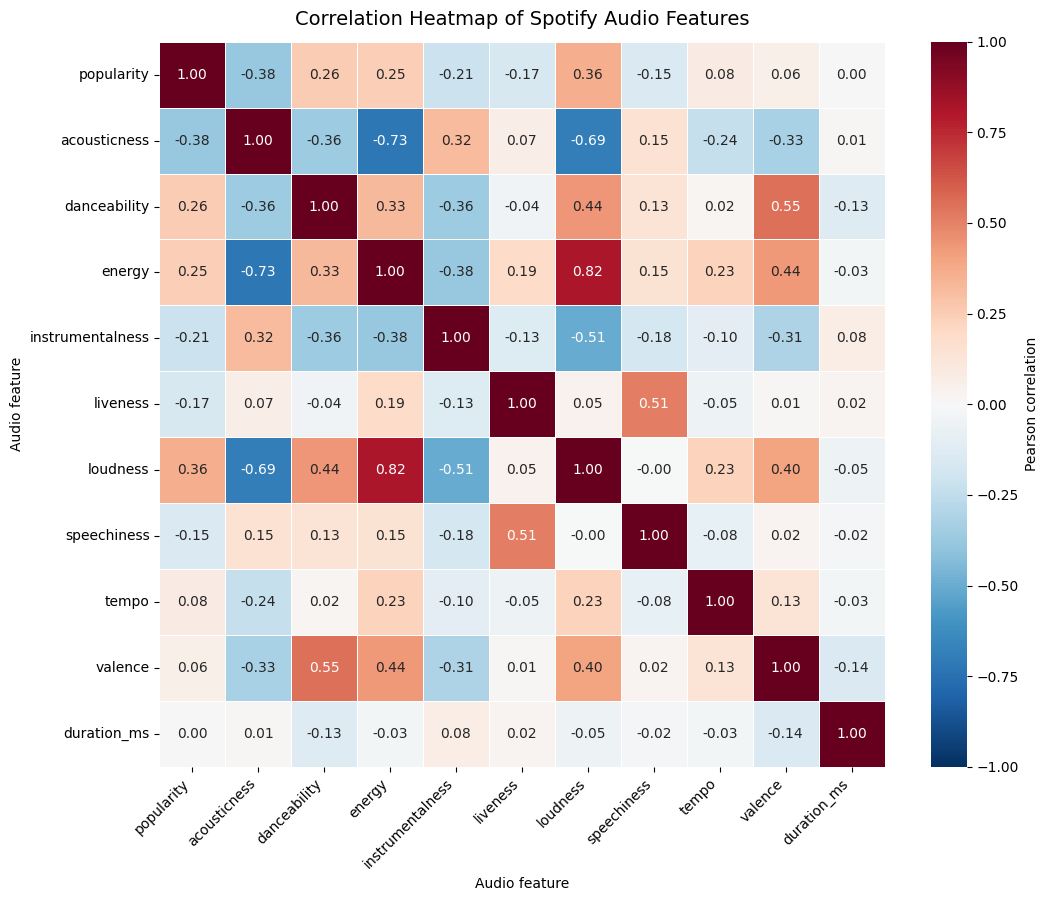

In [4]:
feature_cols = [
    "popularity",
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "duration_ms",
]

corr = df[feature_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Correlation Heatmap of Spotify Audio Features", fontsize=14, pad=12)
ax.set_xlabel("Audio feature")
ax.set_ylabel("Audio feature")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Interactive heatmap (Plotly)

Hover over cells to read exact correlation values. This version is useful for
sharing via Voilà or Binder.

In [5]:
fig = px.imshow(
    corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    aspect="auto",
    labels=dict(color="Correlation"),
    title="Interactive Correlation Heatmap of Spotify Audio Features",
)
fig.update_layout(
    width=800,
    height=700,
    xaxis_title="Audio feature",
    yaxis_title="Audio feature",
)
fig.show()

## Interpretation

The heatmap highlights several musically intuitive relationships:

1. **Energy and loudness are strongly positively correlated.** Louder tracks tend
   to be perceived as more energetic, which matches how Spotify encodes these
   features.
2. **Acousticness is strongly negatively correlated with energy and loudness.**
   Highly acoustic songs (e.g., unplugged or folk-leaning tracks) are typically
   quieter and less energetic than electronic or rock productions.
3. **Danceability and valence tend to move together**, suggesting upbeat,
   positive-sounding tracks are more often danceable.
4. **Popularity shows only modest correlations** with most audio features,
   implying that chart success is not driven by a single acoustic trait alone.

Overall, the visualization shows that Spotify’s audio descriptors form coherent
clusters (loud/energetic vs. acoustic/quiet), while popularity remains a more
complex outcome than any one feature can explain.